# 02C — SMAP feasibility, seasonal availability and forest–terrain screening

**CHT Forest Ecohydrology and Machine Learning** · Rangamati, Bandarban and Khagrachhari · 2017–2022.

**Why this notebook exists:** Notebook 02B found 143 of 179 sampled locations with **zero** quality-approved SMAP AM *or* PM observations across six years. Before building a model, we must check whether this spatial pattern is reproducible, whether usable cells have both seasonal and multi-year coverage, and how it co-varies with forest classification and terrain.

**Inputs:** the original three-district shapefile, `configs/study_config.json`, and your **own local** `outputs/tables/02B_grid_observation_days.csv` from Notebook 02B. If you ran 02B on another machine, copy its CSV into that relative directory before starting.

**Outputs:** small CSV tables and PNG figures on your local PC under `outputs/`. No raster exports, machine-learning training, new Google Cloud assets, edits to source boundaries, or GitHub actions.

Run cells **top to bottom**. Earth Engine calculations may take several minutes. If an error occurs, keep the traceback and share it with the 02C files.


## 1. Read the local 02B result and reattach district names

We use precisely the locations returned by 02B, avoiding an accidental shift to a different grid. The district join is based on each sample point falling *within* the original district polygon. Counts and district means are **sample-point statistics, not area-weighted statistics**.


In [1]:
from pathlib import Path
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ee

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'configs' / 'study_config.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open Jupyter from the research project root or notebooks/ folder.')

CONFIG = json.loads((ROOT / 'configs' / 'study_config.json').read_text(encoding='utf-8'))
SAVE_RESULTS = True  # Set False here if you want a read-only diagnostic session
NAME = CONFIG['district_name_field']
assert CONFIG['study_start'] == '2017-01-01'
assert CONFIG['study_end_exclusive'] == '2023-01-01'
assert CONFIG['smap_collection_for_period'] == 'NASA/SMAP/SPL3SMP_E/005'

districts = gpd.read_file(ROOT / CONFIG['boundary_relative_path'])
assert districts.crs is not None and districts.geometry.is_valid.all()
assert set(districts[NAME]) == set(CONFIG['expected_districts'])
districts = districts.to_crs('EPSG:4326')

prior_file = ROOT / 'outputs' / 'tables' / '02B_grid_observation_days.csv'
if not prior_file.exists():
    raise FileNotFoundError(f'First copy your Notebook 02B grid table here: {prior_file}')

grid = pd.read_csv(prior_file)
required = {'longitude', 'latitude', 'am_qa', 'pm_qa', 'either_qa'}
assert required.issubset(grid.columns), f'Missing columns: {required - set(grid.columns)}'
assert grid[['longitude', 'latitude']].notna().all().all()
assert not grid[['longitude', 'latitude']].duplicated().any(), 'Duplicate sample coordinates.'
grid = grid.reset_index(drop=True).copy()
grid.insert(0, 'cell_id', range(1, len(grid) + 1))  # Analysis IDs, NOT official SMAP grid IDs

points = gpd.GeoDataFrame(grid[['cell_id', 'longitude', 'latitude']].copy(),
                          geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
                          crs='EPSG:4326')
attached = gpd.sjoin(points[['cell_id', 'geometry']], districts[[NAME, 'geometry']],
                     how='left', predicate='within')
if len(attached) != len(grid) or attached[NAME].isna().any():
    raise RuntimeError('Some 02B points cannot be joined uniquely to the original districts. Review geometry before proceeding.')
baseline = grid.merge(attached[['cell_id', NAME]], on='cell_id', validate='one_to_one')
N_CALENDAR_DAYS = (pd.Timestamp('2023-01-01') - pd.Timestamp('2017-01-01')).days

print('Working folder:', ROOT)
print('GEE project:', CONFIG['gee_project_id'])
print('SMAP locations:', len(baseline), '| Zero QA-valid AM:', int((baseline.am_qa == 0).sum()))
print('Zero QA-valid AM or PM:', int((baseline.either_qa == 0).sum()))
print('District counts:', baseline[NAME].value_counts().to_dict())
display(baseline.head())


Working folder: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml
GEE project: axial-paratext-491911-b6
SMAP locations: 179 | Zero QA-valid AM: 143
Zero QA-valid AM or PM: 143
District counts: {'Rangamati': 77, 'Bandarban': 63, 'Khagrachhari': 39}


,cell_id,longitude,latitude,am_qa,pm_qa,either_qa,am_qa_pct_calendar_days,pm_qa_pct_calendar_days,either_qa_pct_calendar_days,adm2_name
0,1,92.256905,23.721009,0,0,0,0.0,0.0,0.0,Rangamati
1,2,92.014360,23.640161,0,0,0,0.0,0.0,0.0,Khagrachhari
2,3,92.095208,23.640161,0,0,0,0.0,0.0,0.0,Rangamati
3,4,92.176056,23.640161,0,0,0,0.0,0.0,0.0,Rangamati
4,5,92.256905,23.640161,0,0,0,0.0,0.0,0.0,Rangamati


## 2. Initialize Earth Engine and reproduce the 02B quality rule

The Earth Engine SMAP v005 catalog defines `retrieval_qual_flag_am/pm == 0` as acceptable retrieval quality. We also require soil moisture between 0 and 1 (volume fraction) and retain the source data mask. Missing or failed values become zero **only in availability indicators**, never in soil-moisture measurements.

We keep AM and PM as distinct passes; `either_good` means at least one QA-approved pass exists on that date. It is **not** an AM/PM-averaged soil-moisture value.

**Sources:** [GEE SMAP v005](https://developers.google.com/earth-engine/datasets/catalog/NASA_SMAP_SPL3SMP_E_005), [Google's SMAP ingestion rules](https://github.com/google/earthengine-catalog/blob/main/pipelines/smap_convert_l3.py), [NSIDC product guidance](https://nsidc.org/data/spl3smp_e/versions/5).


In [2]:
ee.Initialize(project=CONFIG['gee_project_id'])  # MUST precede ee.Geometry construction
SMAP = ee.ImageCollection(CONFIG['smap_collection_for_period'])
REF = ee.Image(SMAP.first()).select('soil_moisture_am').projection()
SAMPLE_SCALE_M = 9000  # Same scale and projection as Notebook 02B

def quality_indicators(image):
    image = ee.Image(image)
    flags = []
    for pass_name in ('am', 'pm'):
        soil = image.select('soil_moisture_' + pass_name)
        qa = image.select('retrieval_qual_flag_' + pass_name)
        valid = soil.gte(0).And(soil.lte(1)).And(qa.eq(0)).unmask(0)
        flags.append(valid.rename(pass_name + '_good').toByte())
    either = flags[0].Or(flags[1]).rename('either_good').toByte()
    return ee.Image.cat(flags + [either])

PASS_TYPES = ('am', 'pm', 'either')
point_features = [ee.Feature(ee.Geometry.Point([float(r.longitude), float(r.latitude)]),
                             {'cell_id': int(r.cell_id)})
                  for r in baseline.itertuples()]
point_fc = ee.FeatureCollection(point_features)

def attributes_only(collection):
    """Fetch feature properties without returning all circle/point coordinates."""
    slim = collection.map(lambda f: ee.Feature(None, ee.Feature(f).toDictionary()))
    return pd.DataFrame([f['properties'] for f in slim.getInfo()['features']])

print('Earth Engine initialized; input grid points:', len(point_features))
print('Native SMAP projection:', REF.getInfo())


Earth Engine initialized; input grid points: 179
Native SMAP projection: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [0.08, 0, -179.99999994985163, 0, -0.08, 85.04450187956549]}


## 3. Six yearly maps of valid days, separated by season

Each year is sampled at the **same 02B locations**. The operational seasons are **May–October** (wetter-month proxy) and **November–April** (drier-month proxy), both counted *within each calendar year*. These are practical screening groups, not a verified climatological classification for every CHT location.

The Earth Engine server computes annual and May–October QA counts. The notebook subtracts May–October from annual counts to derive November–April. Each yearly request may take time; do not rerun repeatedly if an earlier request is still processing.


In [3]:
year_frames = []
for year in range(2017, 2023):
    year_collection = SMAP.filterDate(f'{year}-01-01', f'{year + 1}-01-01')
    wet_collection = year_collection.filter(ee.Filter.calendarRange(5, 10, 'month'))
    annual_img = year_collection.map(quality_indicators).sum().rename(
        ['am_annual', 'pm_annual', 'either_annual'])
    wet_img = wet_collection.map(quality_indicators).sum().rename(
        ['am_wet', 'pm_wet', 'either_wet'])
    combined = annual_img.addBands(wet_img)

    sampled = attributes_only(combined.sampleRegions(
        collection=point_fc, properties=['cell_id'],
        projection=REF, scale=SAMPLE_SCALE_M, tileScale=4, geometries=False))
    if len(sampled) != len(baseline) or sampled['cell_id'].duplicated().any():
        raise RuntimeError(f'Year {year}: grid locations not sampled uniquely. Stop and inspect alignment.')

    sampled['year'] = year
    sampled['calendar_days'] = (pd.Timestamp(f'{year + 1}-01-01') -
                                pd.Timestamp(f'{year}-01-01')).days
    sampled['wet_calendar_days'] = (pd.Timestamp(f'{year}-11-01') -
                                    pd.Timestamp(f'{year}-05-01')).days
    sampled['dry_calendar_days'] = sampled['calendar_days'] - sampled['wet_calendar_days']

    for p in PASS_TYPES:
        sampled[p + '_dry'] = sampled[p + '_annual'] - sampled[p + '_wet']
        for season, denominator in [('annual', 'calendar_days'),
                                    ('wet', 'wet_calendar_days'),
                                    ('dry', 'dry_calendar_days')]:
            sampled[p + '_' + season + '_pct'] = (
                100 * sampled[p + '_' + season] / sampled[denominator])
    year_frames.append(sampled)
    print('Finished QA count for', year, '-', len(sampled), 'grid samples')

annual = pd.concat(year_frames, ignore_index=True)
annual = annual.merge(baseline[['cell_id', NAME]], on='cell_id', validate='many_to_one')
assert (annual[[p + '_dry' for p in PASS_TYPES]] >= 0).all().all()
print('Year × grid records:', len(annual))
display(annual[[NAME, 'cell_id', 'year', 'am_annual', 'am_wet', 'am_dry',
                'pm_annual', 'either_annual']].head(12))


Finished QA count for 2017 - 179 grid samples
Finished QA count for 2018 - 179 grid samples
Finished QA count for 2019 - 179 grid samples
Finished QA count for 2020 - 179 grid samples
Finished QA count for 2021 - 179 grid samples
Finished QA count for 2022 - 179 grid samples
Year × grid records: 1074


,adm2_name,cell_id,year,am_annual,am_wet,am_dry,pm_annual,either_annual
0,Rangamati,1,2017,0,0,0,0,0
1,Khagrachhari,2,2017,0,0,0,0,0
2,Rangamati,3,2017,0,0,0,0,0
3,Rangamati,4,2017,0,0,0,0,0
4,Rangamati,5,2017,0,0,0,0,0
5,Khagrachhari,6,2017,0,0,0,0,0
6,Khagrachhari,7,2017,0,0,0,0,0
7,Rangamati,8,2017,0,0,0,0,0
8,Rangamati,9,2017,0,0,0,0,0
9,Khagrachhari,10,2017,0,0,0,0,0


## 4. **Required consistency check** against Notebook 02B

The sum of the six annual counts should reproduce 02B's original AM, PM, and either-pass full-period counts for **each** sampled location. This checks the geometry, sampling projection and indicator logic together. If locations differ, **do not use any subsequent plots for research conclusions until the mismatch is resolved**.


In [4]:
full_counts = annual.groupby('cell_id')[[p + '_annual' for p in PASS_TYPES]].sum().reset_index()
alignment = baseline[['cell_id', NAME, 'longitude', 'latitude'] +
                     [p + '_qa' for p in PASS_TYPES]].merge(
    full_counts, on='cell_id', validate='one_to_one')
for p in PASS_TYPES:
    alignment[p + '_count_difference'] = alignment[p + '_annual'] - alignment[p + '_qa']

delta_cols = [p + '_count_difference' for p in PASS_TYPES]
failed_rows = alignment[alignment[delta_cols].abs().sum(axis=1) != 0]
qa_alignment_pass = failed_rows.empty
print('02B/02C counts agree at all grid points:', qa_alignment_pass)
print('Mismatched points:', len(failed_rows))
if not qa_alignment_pass:
    display(failed_rows.head(20))
    if SAVE_RESULTS:
        audit_dir = ROOT / 'outputs' / 'tables'
        audit_dir.mkdir(parents=True, exist_ok=True)
        alignment.to_csv(audit_dir / '02C_02B_alignment_audit.csv', index=False)
        print('Saved mismatch audit:', audit_dir / '02C_02B_alignment_audit.csv')
    raise RuntimeError('STOP: 02B and 02C QA counts disagree. Share alignment audit before proceeding.')
else:
    print('PASS: annual series reproduces all six-year 02B QA counts.')


02B/02C counts agree at all grid points: True
Mismatched points: 0
PASS: annual series reproduces all six-year 02B QA counts.


## 5. Landscape screening around each coarse-grid location

We ask whether the SMAP observations are disproportionately missing in forest-classified or rugged landscapes. The following are **spatial associations only**.

- **MODIS MCD12Q1 v061, 2021, 500 m:** IGBP land-cover classes 1–5 treated as *forest-classified*. This is an approximate land-cover classification, not field-measured forest percentage.
- **NASADEM, approximately 30 m:** elevation and derived terrain slope.
- **Neighborhood:** a **4.5 km-radius circle** around each 02B center. Its forest fraction and terrain means are *proxies* for the local setting. It is **not** the SMAP sensor's effective measurement footprint or an exact 9 km grid-cell polygon. Neighborhood circles can overlap.

Terrain is summarized at 150 m for manageable exploratory computation, while land cover uses the native approximate 500 m scale. Because these resolutions differ, treat the outputs as descriptive covariates—not definitive explanations for SMAP failures.

Sources: [MODIS land cover](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MCD12Q1), [NASADEM](https://developers.google.com/earth-engine/datasets/catalog/NASA_NASADEM_HGT_001), [GEE zonal statistics](https://developers.google.com/earth-engine/apidocs/ee-image-reduceregions).


In [5]:
LANDCOVER_YEAR = 2021  # One fixed context year inside the 2017–2022 study window
NEIGHBORHOOD_RADIUS_M = 4500
modis_collection = ee.ImageCollection('MODIS/061/MCD12Q1').filterDate(
    f'{LANDCOVER_YEAR}-01-01', f'{LANDCOVER_YEAR + 1}-01-01')
assert modis_collection.size().getInfo() > 0, 'MODIS 2021 land cover is not available.'
igbp = ee.Image(modis_collection.first()).select('LC_Type1')
forest = igbp.gte(1).And(igbp.lte(5)).toFloat().rename('forest_fraction_proxy')

dem = ee.Image('NASA/NASADEM_HGT/001').select('elevation')
terrain = ee.Image.cat([dem.rename('mean_elevation_m'),
                        ee.Terrain.slope(dem).rename('mean_slope_deg')])
neighborhoods = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([float(r.longitude), float(r.latitude)])
               .buffer(NEIGHBORHOOD_RADIUS_M), {'cell_id': int(r.cell_id)})
    for r in baseline.itertuples()])

forest_reduced = forest.reduceRegions(
    collection=neighborhoods, reducer=ee.Reducer.mean(), scale=500, tileScale=4)
forest_table = attributes_only(forest_reduced)
if 'forest_fraction_proxy' not in forest_table.columns and 'mean' in forest_table.columns:
    forest_table = forest_table.rename(columns={'mean': 'forest_fraction_proxy'})
assert {'cell_id', 'forest_fraction_proxy'}.issubset(forest_table.columns), (
    f'Unexpected MODIS output columns: {forest_table.columns.tolist()}')

terrain_reduced = terrain.reduceRegions(
    collection=neighborhoods, reducer=ee.Reducer.mean(), scale=150, tileScale=4)
terrain_table = attributes_only(terrain_reduced)
assert {'cell_id', 'mean_elevation_m', 'mean_slope_deg'}.issubset(terrain_table.columns), (
    f'Unexpected NASADEM output columns: {terrain_table.columns.tolist()}')

landscape = forest_table[['cell_id', 'forest_fraction_proxy']].merge(
    terrain_table[['cell_id', 'mean_elevation_m', 'mean_slope_deg']],
    on='cell_id', validate='one_to_one')
assert len(landscape) == len(baseline), 'At least one landscape neighborhood was lost.'
print('Forest/terrain neighborhoods:', len(landscape))
display(landscape.describe())


Forest/terrain neighborhoods: 179


,cell_id,forest_fraction_proxy,mean_elevation_m,mean_slope_deg
count,179.000000,179.000000,179.000000,179.000000
mean,90.000000,0.345895,148.727382,7.551731
std,51.816986,0.237049,110.719860,4.185273
min,1.000000,0.000000,20.153025,1.626457
25%,45.500000,0.144542,70.632359,4.120918
50%,90.000000,0.335044,117.771351,6.754759
75%,134.500000,0.502695,187.957827,10.179044
max,179.000000,0.927830,649.759123,19.139352


## 6. Summarize temporal support and exploratory model feasibility

The column `illustrative_screen_only` identifies a **starting point for discussion**, *not* an established statistical criterion or the final training mask: at least 365 valid AM days during the study period and at least one valid AM day in both operational seasons in at least four different calendar years. These conditions may need to be stricter after inspecting actual gap lengths, covariates and blocked hold-out feasibility.

Do not use no-target locations as supervised training or validation labels. A cell with no SMAP observations may still have predictor data; that is not the same as having an observable soil-moisture target.


In [6]:
annual['year_has_am'] = annual['am_annual'] > 0
annual['year_has_wet_am'] = annual['am_wet'] > 0
annual['year_has_dry_am'] = annual['am_dry'] > 0
temporal = annual.groupby('cell_id', as_index=False).agg(
    years_with_any_am=('year_has_am', 'sum'),
    years_with_wet_am=('year_has_wet_am', 'sum'),
    years_with_dry_am=('year_has_dry_am', 'sum'),
    min_annual_am_days=('am_annual', 'min'),
    median_annual_am_days=('am_annual', 'median'))

cells = baseline.merge(temporal, on='cell_id', validate='one_to_one').merge(
    landscape, on='cell_id', validate='one_to_one')
cells['any_am_qa'] = cells['am_qa'] > 0
cells['illustrative_screen_only'] = (
    (cells['am_qa'] >= 365) &
    (cells['years_with_any_am'] >= 4) &
    (cells['years_with_wet_am'] >= 4) &
    (cells['years_with_dry_am'] >= 4))

district_summary = cells.groupby(NAME, as_index=False).agg(
    sampled_points=('cell_id', 'size'),
    points_with_any_am=('any_am_qa', 'sum'),
    illustrative_screen_points=('illustrative_screen_only', 'sum'),
    median_am_good_days=('am_qa', 'median'),
    mean_forest_proxy=('forest_fraction_proxy', 'mean'),
    mean_elevation_m=('mean_elevation_m', 'mean'),
    mean_slope_deg=('mean_slope_deg', 'mean'))

annual_summary = annual.groupby(['year', NAME], as_index=False).agg(
    mean_am_annual_pct=('am_annual_pct', 'mean'),
    mean_am_wet_pct=('am_wet_pct', 'mean'),
    mean_am_dry_pct=('am_dry_pct', 'mean'),
    mean_either_annual_pct=('either_annual_pct', 'mean'),
    locations_with_any_am=('year_has_am', 'sum'))

print('Locations passing ILLUSTRATIVE temporal-support screen:',
      int(cells['illustrative_screen_only'].sum()), 'of', len(cells))
display(district_summary.round(2))
display(annual_summary.round(2))


Locations passing ILLUSTRATIVE temporal-support screen: 30 of 179


,adm2_name,sampled_points,points_with_any_am,illustrative_screen_points,median_am_good_days,mean_forest_proxy,mean_elevation_m,mean_slope_deg
0,Bandarban,63,11,9,0.0,0.33,192.04,9.87
1,Khagrachhari,39,23,20,434.0,0.23,94.28,4.20
2,Rangamati,77,2,1,0.0,0.41,140.86,7.35


,year,adm2_name,mean_am_annual_pct,mean_am_wet_pct,mean_am_dry_pct,mean_either_annual_pct,locations_with_any_am
0,2017,Bandarban,4.73,2.73,6.76,6.99,11
1,2017,Khagrachhari,20.27,16.46,24.15,29.98,23
2,2017,Rangamati,0.51,0.33,0.68,0.76,2
3,2018,Bandarban,4.96,2.96,7.00,7.20,11
4,2018,Khagrachhari,19.96,15.83,24.15,28.24,23
5,2018,Rangamati,0.54,0.40,0.70,0.80,2
6,2019,Bandarban,4.73,2.81,6.67,6.34,11
7,2019,Khagrachhari,19.33,14.81,23.91,24.95,23
8,2019,Rangamati,0.53,0.38,0.68,0.70,2
9,2020,Bandarban,5.04,3.38,6.72,6.57,11


## 7. Figures for the feasibility review

Figure A uses average **observed-day percentages** across the same 179 locations for each year and operational season. Figure B is a descriptive scatterplot, with no implication that forest cover or slope *caused* SMAP's retrieval-quality exclusions. Correlated neighboring samples are not independent experimental replicates.


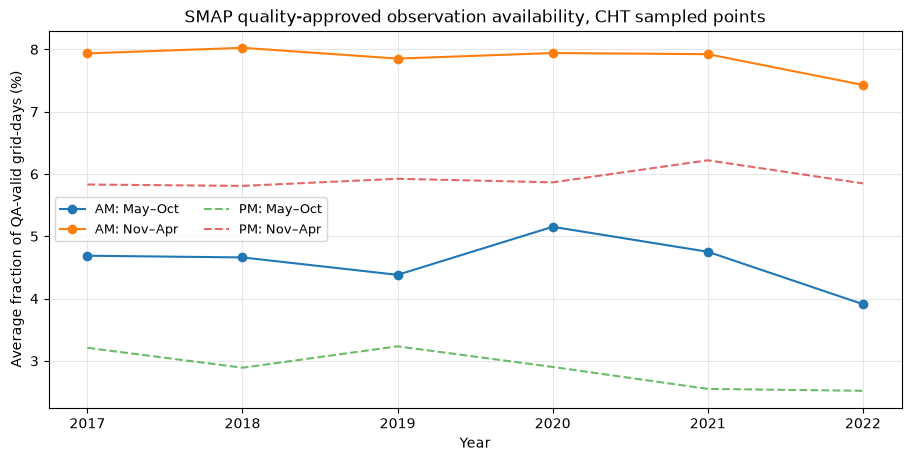

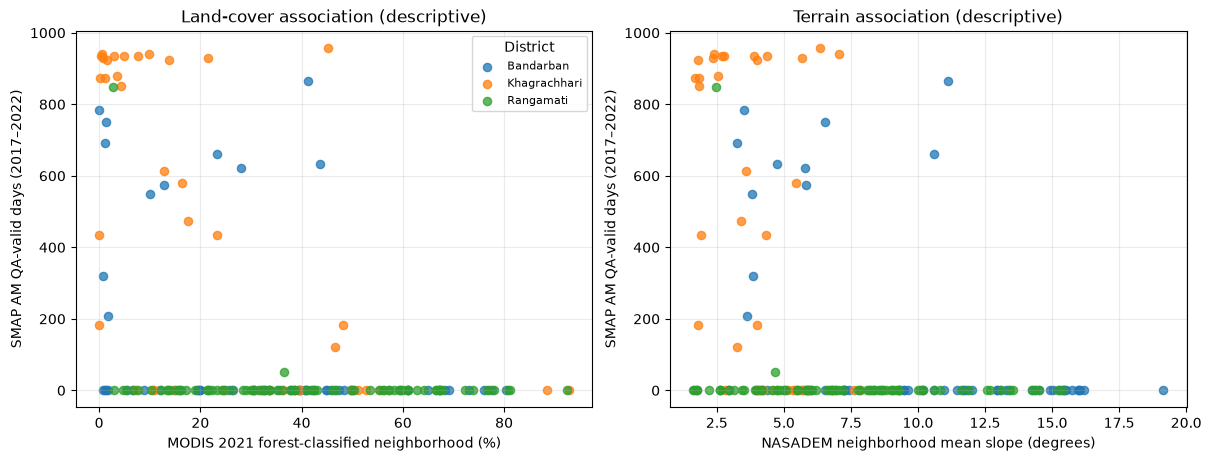

In [7]:
seasonal_years = annual.groupby('year', as_index=False)[
    ['am_wet_pct', 'am_dry_pct', 'pm_wet_pct', 'pm_dry_pct']].mean()

fig_year, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.plot(seasonal_years.year, seasonal_years.am_wet_pct, 'o-', label='AM: May–Oct')
ax.plot(seasonal_years.year, seasonal_years.am_dry_pct, 'o-', label='AM: Nov–Apr')
ax.plot(seasonal_years.year, seasonal_years.pm_wet_pct, '--', alpha=0.7,
        label='PM: May–Oct')
ax.plot(seasonal_years.year, seasonal_years.pm_dry_pct, '--', alpha=0.7,
        label='PM: Nov–Apr')
ax.set(xlabel='Year', ylabel='Average fraction of QA-valid grid-days (%)',
       title='SMAP quality-approved observation availability, CHT sampled points')
ax.grid(alpha=0.3)
ax.legend(ncol=2, fontsize=9)
plt.show()

fig_landscape, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for district, group in cells.groupby(NAME):
    axes[0].scatter(100 * group.forest_fraction_proxy, group.am_qa,
                    label=district, s=35, alpha=0.75)
    axes[1].scatter(group.mean_slope_deg, group.am_qa,
                    label=district, s=35, alpha=0.75)
axes[0].set(xlabel='MODIS 2021 forest-classified neighborhood (%)',
            ylabel='SMAP AM QA-valid days (2017–2022)',
            title='Land-cover association (descriptive)')
axes[1].set(xlabel='NASADEM neighborhood mean slope (degrees)',
            ylabel='SMAP AM QA-valid days (2017–2022)',
            title='Terrain association (descriptive)')
for ax in axes:
    ax.grid(alpha=0.25)
axes[0].legend(title='District', fontsize=8)
plt.show()


## 8. Save the local evidence package

Files are placed under `outputs/tables/` and `outputs/figures/`. If the 02B/02C count audit failed, only the **alignment-audit CSV** is saved; all other results are withheld until we fix the mismatch. Set `SAVE_RESULTS = False` to run without writing any outputs.


In [8]:
if SAVE_RESULTS:
    tables = ROOT / 'outputs' / 'tables'
    figures = ROOT / 'outputs' / 'figures'
    tables.mkdir(parents=True, exist_ok=True)
    figures.mkdir(parents=True, exist_ok=True)
    alignment.to_csv(tables / '02C_02B_alignment_audit.csv', index=False)
    print('Saved alignment audit:', tables / '02C_02B_alignment_audit.csv')

    if qa_alignment_pass:
        annual.to_csv(tables / '02C_annual_seasonal_cell_counts.csv', index=False)
        cells.to_csv(tables / '02C_grid_feasibility_and_landscape.csv', index=False)
        district_summary.to_csv(tables / '02C_district_feasibility_summary.csv', index=False)
        annual_summary.to_csv(tables / '02C_district_annual_availability.csv', index=False)
        fig_year.savefig(figures / '02C_annual_seasonal_coverage.png', dpi=180,
                         bbox_inches='tight')
        fig_landscape.savefig(figures / '02C_landscape_availability_associations.png',
                              dpi=180, bbox_inches='tight')
        print('Saved four 02C research tables and two figures.')
    else:
        print('AUDIT FAILED: other outputs intentionally not saved.')
else:
    print('SAVE_RESULTS=False: no files written.')


Saved alignment audit: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml\outputs\tables\02C_02B_alignment_audit.csv
Saved four 02C research tables and two figures.


## 9. Stop here — evidence review before Notebook 03

Please send these files after the notebook finishes:

1. **`02C_02B_alignment_audit.csv`** — necessary even if the QA alignment check fails.
2. `02C_grid_feasibility_and_landscape.csv` — where SMAP AM is observed, by year/season and landscape.
3. `02C_district_feasibility_summary.csv` and `02C_district_annual_availability.csv` — whether enough target support exists in each district.
4. The two `02C_*.png` figures (helpful, not a substitute for the CSVs).

### Decision rules (to be agreed, not automatic)

- If 02B and 02C do **not** reproduce the same six-year QA counts, resolve the projection/mask alignment first.
- If forested/rugged sample neighborhoods are poorly observed, do **not** claim that a model trained on the more observable cells generalizes to all forests or all three districts.
- If any subset has sufficiently distributed observations across years, wet/dry seasons and gap lengths, a **limited-domain** SMAP reconstruction might still be testable using masked and temporally withheld SMAP measurements.
- If the primary scientific objective requires an all-CHT map, discuss revising the research target to forest ecohydrological indicators or a model-based soil-moisture product, while explicitly distinguishing satellite retrievals, modeled estimates, and any eventual **independent ground validation**.

**No ground validation is conducted by this notebook.** There is no independent evidence here for true field soil-water accuracy, interception, infiltration, root-zone moisture, or forest causal effects. Do not advance to full-scale modeling or publication-quality maps until we jointly review this diagnostic.
